In [1]:
import numpy as np 
import matplotlib.pyplot as plt 


On extrait une matrice de covariance estimée pour l'event 9 des données ACOUPLANE (portion 5, AIS). 

Lors de l'event 9 le signal de l'OBS 2 n'est pas dispo et la matrice à donc des 0 sur toute la ligne (respectivement la colonne) associée à l'OBS 2. 

In [123]:
# CSDM of event 9 (AIS acouplane, freq=250, event_datetime_i=10)
csdm = np.array(
    [
        [
            8.59807446e-09 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
            2.08618323e-09 - 2.45028796e-09j,
            2.80384271e-09 + 4.13768619e-09j,
            -3.60283066e-10 + 9.26419068e-10j,
            1.49524709e-08 - 5.49688350e-09j,
        ],
        [
            0.00000000e00 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
            0.00000000e00 + 0.00000000e00j,
        ],
        [
            2.08618323e-09 + 2.45028796e-09j,
            0.00000000e00 + 0.00000000e00j,
            9.43057085e-09 + 0.00000000e00j,
            -2.41936276e-09 + 5.52151116e-09j,
            3.17284340e-10 - 6.16808512e-10j,
            5.32245058e-09 - 1.77946773e-09j,
        ],
        [
            2.80384271e-09 - 4.13768619e-09j,
            0.00000000e00 + 0.00000000e00j,
            -2.41936276e-09 - 5.52151116e-09j,
            9.24468800e-09 + 0.00000000e00j,
            -2.78255578e-09 + 1.69296567e-09j,
            4.01220067e-09 - 3.55062235e-09j,
        ],
        [
            -3.60283066e-10 - 9.26419068e-10j,
            0.00000000e00 + 0.00000000e00j,
            3.17284340e-10 + 6.16808512e-10j,
            -2.78255578e-09 - 1.69296567e-09j,
            4.23596885e-09 + 0.00000000e00j,
            -8.03961012e-09 - 6.82025426e-09j,
        ],
        [
            1.49524709e-08 + 5.49688350e-09j,
            0.00000000e00 + 0.00000000e00j,
            5.32245058e-09 + 1.77946773e-09j,
            4.01220067e-09 + 3.55062235e-09j,
            -8.03961012e-09 + 6.82025426e-09j,
            7.18331087e-08 + 0.00000000e00j,
        ],
    ]
)
csdm

array([[ 8.59807446e-09+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         2.08618323e-09-2.45028796e-09j,  2.80384271e-09+4.13768619e-09j,
        -3.60283066e-10+9.26419068e-10j,  1.49524709e-08-5.49688350e-09j],
       [ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j],
       [ 2.08618323e-09+2.45028796e-09j,  0.00000000e+00+0.00000000e+00j,
         9.43057085e-09+0.00000000e+00j, -2.41936276e-09+5.52151116e-09j,
         3.17284340e-10-6.16808512e-10j,  5.32245058e-09-1.77946773e-09j],
       [ 2.80384271e-09-4.13768619e-09j,  0.00000000e+00+0.00000000e+00j,
        -2.41936276e-09-5.52151116e-09j,  9.24468800e-09+0.00000000e+00j,
        -2.78255578e-09+1.69296567e-09j,  4.01220067e-09-3.55062235e-09j],
       [-3.60283066e-10-9.26419068e-10j,  0.00000000e+00+0.00000000e+00j,
         3.17284340e-10+6.16808512

In [124]:
print(csdm[1, :])

[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]


In [27]:
rcv_i = ["obs1", "obs2", "obs4", "obs5", "obs6", "obs7"]
obs2_idx = rcv_i.index("obs2")
print(rcv_i, obs2_idx)

['obs1', 'obs2', 'obs4', 'obs5', 'obs6', 'obs7'] 1


0j [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j] [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]


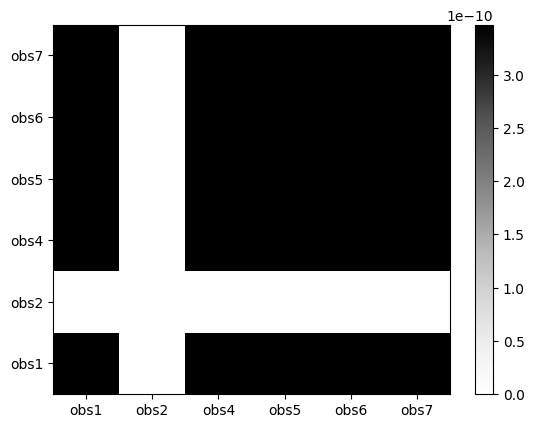

In [28]:
print(csdm[obs2_idx, obs2_idx], csdm[:, obs2_idx], csdm[obs2_idx, :])

plt.figure()
im = plt.pcolormesh(
    rcv_i, rcv_i, np.abs(csdm), cmap="Grays", vmin=0, vmax=np.percentile(np.abs(csdm), 30)
)
plt.colorbar(im)

In [40]:
from scipy.linalg import eigh

major_eigval, major_eigve = eigh(
    csdm,
    check_finite=False,
    # subset_by_index=[6 - 1, 6 - 1],  # Only get the major eigenvector
)
major_eigve.shape, major_eigval

((6, 6),
 array([-1.97747865e-24,  3.35965122e-10,  2.92951974e-09,  4.76417116e-09,
         1.70752431e-08,  7.82375117e-08]))

In [41]:
major_eigval = major_eigval[::-1]
major_eigve = major_eigve[:, -1]

Text(0, 0.5, 'Eigen value')

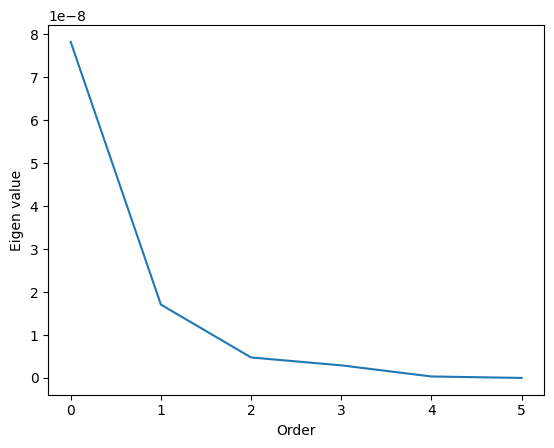

In [42]:
plt.figure()
plt.plot(major_eigval)
plt.xlabel("Order")
plt.ylabel("Eigen value")

In [43]:
major_eigve

array([-2.29542188e-01-0.00000000e+00j, -1.11022302e-16-3.64291930e-17j,
       -8.40863764e-02-1.86715603e-02j, -8.27557867e-02+4.51316853e-02j,
        7.22361903e-02+1.20537750e-01j, -8.96519209e-01-3.27889829e-01j])

In [44]:
idx_rcv_ref = rcv_i.index("obs1")
pi = major_eigve / major_eigve[idx_rcv_ref]
pi

array([ 1.00000000e+00-0.00000000e+00j,  4.83668399e-16+1.58703694e-16j,
        3.66322101e-01+8.13426084e-02j,  3.60525390e-01-1.96616081e-01j,
       -3.14696793e-01-5.25122425e-01j,  3.90568382e+00+1.42845127e+00j])

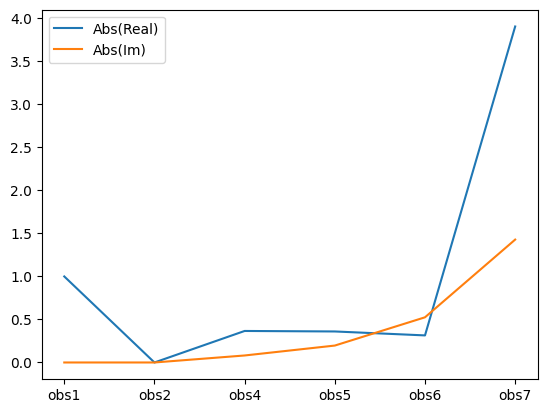

In [50]:
plt.plot(rcv_i, np.abs(np.real(pi)), label="Abs(Real)")
plt.plot(rcv_i, np.abs(np.imag(pi)), label="Abs(Im)")
plt.legend()

Comme on peut le constater, la partie imaginaire et la partie réelle associée au capteur 2 sont très faibles mais ne sont pas identiquement nulle. Dans le cas des données ACOUPLANE cette composante semble tout de même encoder de l'information. Il ne peut vraisemblablement s'agir que de l'information du capteur 1.  

# Test PEkeris 

In [51]:
import sys
import numpy as np

In [52]:
from illustration_rtf.src.sensitivity import (
    baseline_env,
    baseline_sig,
    baseline_src_rcv,
    calc_gamma_dist,
    calc_mainlobe_width_3dB,
    calc_monotonicity_domain, 
    # run_single_sensibility_test,
)
from source.normal_modes import * 
from publication.publication_figure import color, set_subfigures_abc_labels

In [53]:
# Environment
env_param = baseline_env()
print("Baseline environement properties:")
for k in env_param.keys():
    print(f"\t{k} = {env_param[k]}")

# Signal
sig_param = baseline_sig()
print("Baseline signal properties:")
for k in sig_param.keys():
    print(f"\t{k} = {sig_param[k]}")

# Source receiver config
src_rcv_param = baseline_src_rcv()
print("Baseline src / rcv configuration:")
for k in src_rcv_param.keys():
    print(f"\t{k} = {src_rcv_param[k]}")

Baseline environement properties:
	c1 = 1500
	c2 = 1600
	rho1 = 1000.0
	rho2 = 1800.0
	attn2 = 0.8
	depth = 100
Baseline signal properties:
	freq = [  0.    0.2   0.4   0.6   0.8   1.    1.2   1.4   1.6   1.8   2.    2.2
   2.4   2.6   2.8   3.    3.2   3.4   3.6   3.8   4.    4.2   4.4   4.6
   4.8   5.    5.2   5.4   5.6   5.8   6.    6.2   6.4   6.6   6.8   7.
   7.2   7.4   7.6   7.8   8.    8.2   8.4   8.6   8.8   9.    9.2   9.4
   9.6   9.8  10.   10.2  10.4  10.6  10.8  11.   11.2  11.4  11.6  11.8
  12.   12.2  12.4  12.6  12.8  13.   13.2  13.4  13.6  13.8  14.   14.2
  14.4  14.6  14.8  15.   15.2  15.4  15.6  15.8  16.   16.2  16.4  16.6
  16.8  17.   17.2  17.4  17.6  17.8  18.   18.2  18.4  18.6  18.8  19.
  19.2  19.4  19.6  19.8  20.   20.2  20.4  20.6  20.8  21.   21.2  21.4
  21.6  21.8  22.   22.2  22.4  22.6  22.8  23.   23.2  23.4  23.6  23.8
  24.   24.2  24.4  24.6  24.8  25.   25.2  25.4  25.6  25.8  26.   26.2
  26.4  26.6  26.8  27.   27.2  27.4  27.6  27.8  2

In [54]:
# Environment
c1 = env_param.get("c1", None)
c2 = env_param.get("c2", None)
rho1 = env_param.get("rho1", None)
rho2 = env_param.get("rho2", None)
attn2 = env_param.get("attn2", None)
d = env_param.get("depth", None)

# Signal
freq = sig_param.get("freq", None)
fs = sig_param.get("fs", None)
fmax = sig_param.get("fmax", None)

# Source / receiver
z_s = src_rcv_param.get("z_s", 5)
z = src_rcv_param.get("z_rcv", 20)
# r_grid = src_rcv_param.get("r_rcv", np.array([1e4]))
r_grid = np.arange(5 * 1e3, 25 * 1e3 + 50, 50)  

r0 = src_rcv_param.get("r0", 1e4)
d12 = src_rcv_param.get("d12", 100)

In [56]:
dr = r_grid[1] - r_grid[0]
r_grid_add = np.arange(r_grid[-1] + dr, r_grid[-1] + dr + d12, dr)
r_grid_ = np.append(r_grid, r_grid_add)
g_fr = pekeris_green_fct(freq, c1, c2, rho1, rho2, attn2, d, z_s, z, r_grid_)

nr_shift = int(d12 / dr)
# Green function at receiver 1
g_fr_1 = g_fr[:, 0:-nr_shift]
idx_1_r0 = np.argmin(np.abs(r_grid - r0))
gf1_r0 = g_fr_1[:, idx_1_r0]

# Green function at receiver 2
g_fr_2 = g_fr[:, 1*nr_shift:]
idx_2_r0 = np.argmin(np.abs(r_grid - r0))
gf2_r0 = g_fr_2[:, idx_2_r0]

# Green function at receiver 3
g_fr_3 = g_fr[:, 2*nr_shift:]
idx_3_r0 = np.argmin(np.abs(r_grid - r0))
gf3_r0 = g_fr_3[:, idx_3_r0]

# Green function at receiver 4
g_fr_4 = g_fr[:, 3*nr_shift:]
idx_4_r0 = np.argmin(np.abs(r_grid - r0))
gf4_r0 = g_fr_4[:, idx_4_r0]


c:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:326: RuntimeWarning: invalid value encountered in sqrt
  idx_krm_lt_k2, np.sqrt(k2**2 - krm**2), 1j * np.sqrt(krm**2 - k2**2)
c:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:618: RuntimeWarning: divide by zero encountered in divide
  lambd = c / f
c:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:582: RuntimeWarning: invalid value encountered in divide
  (1j * alpha_2_2d * omega_2d)
c:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:518: RuntimeWarning: invalid value encountered in sqrt
  / np.sqrt(krm[..., np.newaxis])
c:\Users\baptiste.menetrier\Desktop\devPy\phd\source\normal_modes.py:516: RuntimeWarning: invalid value encountered in divide
  Am[..., np.newaxis]


Text(0.5, 0.01, 'Fréquence [Hz]')

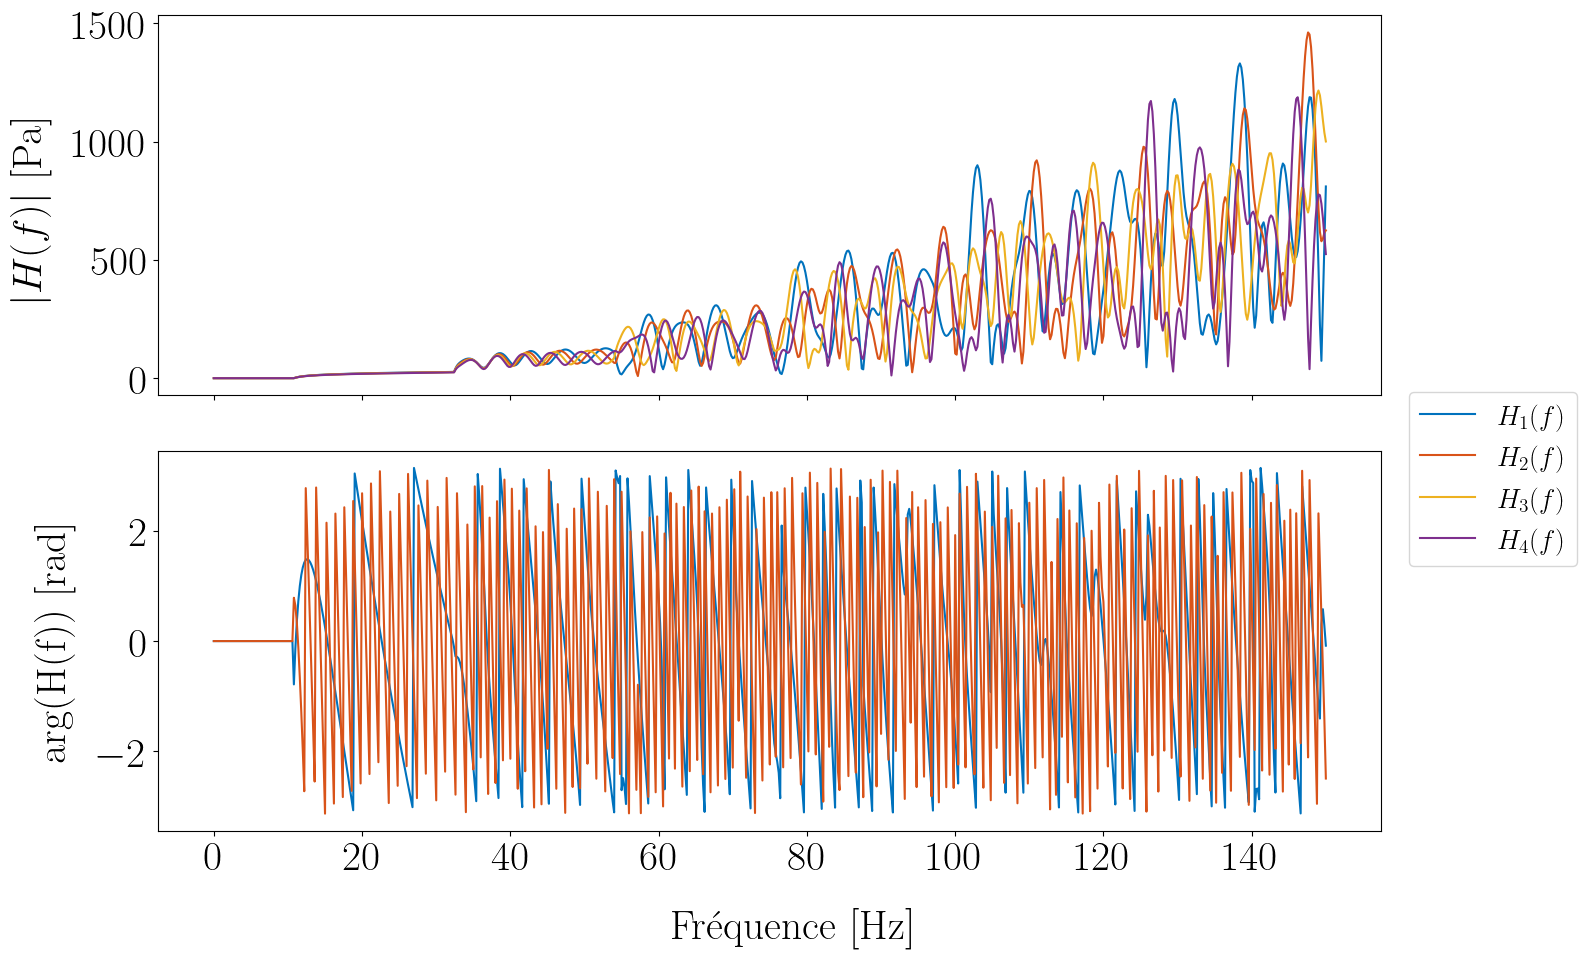

In [60]:
fig, axs = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Amplitude
axs[0].plot(freq, np.abs(gf1_r0), color=color(0))
axs[0].plot(freq, np.abs(gf2_r0), color=color(1))
axs[0].plot(freq, np.abs(gf3_r0), color=color(2))
axs[0].plot(freq, np.abs(gf4_r0), color=color(3))


axs[0].set_ylabel(r"$\lvert H(f) \rvert$ [Pa]")

# Phase
axs[1].plot(freq, np.angle(gf1_r0), color=color(0))
axs[1].plot(freq, np.angle(gf2_r0), color=color(1))

axs[1].set_ylabel("arg(H(f)) [rad]")

legend_handles = [
    Line2D([0], [0], color=color(i), linestyle="-", label=f"$H_{i+1}(f)$") for i in [0, 1, 2, 3]
]

fig.legend(handles=legend_handles, loc="outside center right")

fig.suptitle("")

fig.supxlabel("Fréquence [Hz]")
# fig.suptitle(rf"z_s = {z_s:.1f} m, z_r = {z_r:.1f} m, r = {r:.1f} m")
# for ax in axs:
#     ax.legend()

In [58]:
pi_21_r0 = gf2_r0 / gf1_r0
pi_31_r0 = gf3_r0 / gf1_r0
pi_41_r0 = gf4_r0 / gf1_r0

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\1038634464.py:1: RuntimeWarning: invalid value encountered in divide
  pi_21_r0 = gf2_r0 / gf1_r0
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\1038634464.py:2: RuntimeWarning: invalid value encountered in divide
  pi_31_r0 = gf3_r0 / gf1_r0
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\1038634464.py:3: RuntimeWarning: invalid value encountered in divide
  pi_41_r0 = gf4_r0 / gf1_r0


Text(0.5, 0.01, 'Fréquence [Hz]')

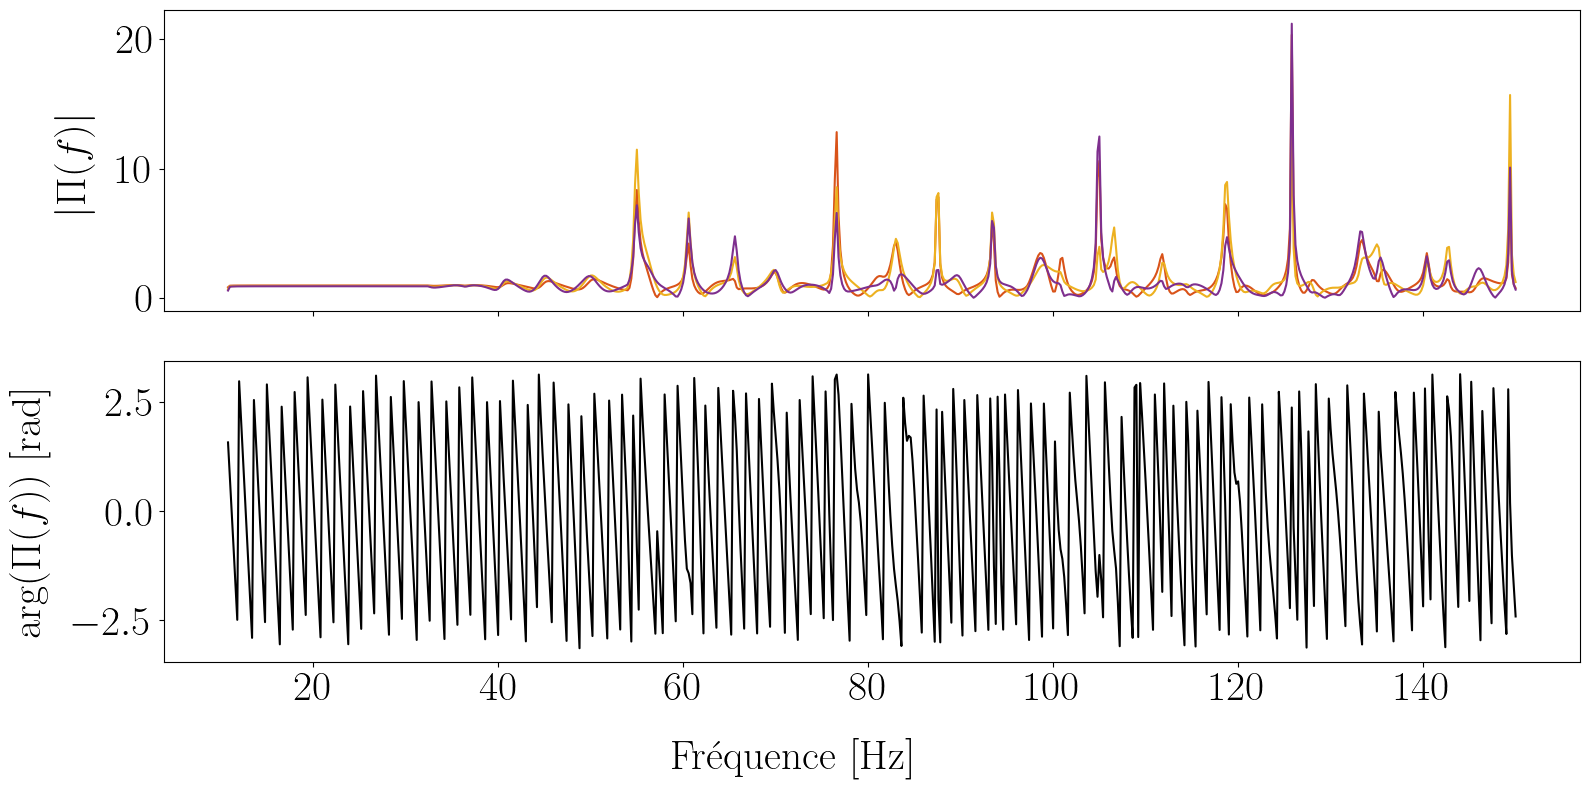

In [59]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Amplitude
axs[0].plot(freq, np.abs(pi_21_r0), color=color(1), label="$\Pi_{21}(f)$")
axs[0].plot(freq, np.abs(pi_31_r0), color=color(2), label="$\Pi_{31}(f)$")
axs[0].plot(freq, np.abs(pi_41_r0), color=color(3), label="$\Pi_{41}(f)$")

axs[0].set_ylabel(r"$\lvert \Pi(f) \rvert$")

# Phase
axs[1].plot(freq, np.angle(pi_21_r0), color="k", label="$\Pi(f)$")
axs[1].set_ylabel(r"arg($\Pi(f)$) [rad]")

# for ax in axs.flatten():
#     ax.set_xlim(freq[0], freq[-1])
# for ax in axs.flatten():
#     for i, fc in enumerate(f_c):
#         lab = f"c_{i+1}"
#         ax.axvline(fc, linestyle="--", color=color(i), label=rf"$f_{{{lab}}}$")
#     ax.legend(fontsize=16)

fig.supxlabel("Fréquence [Hz]")
# plt.xlim(0, fmax)

Text(0.5, 0, 'Fréquence [Hz]')

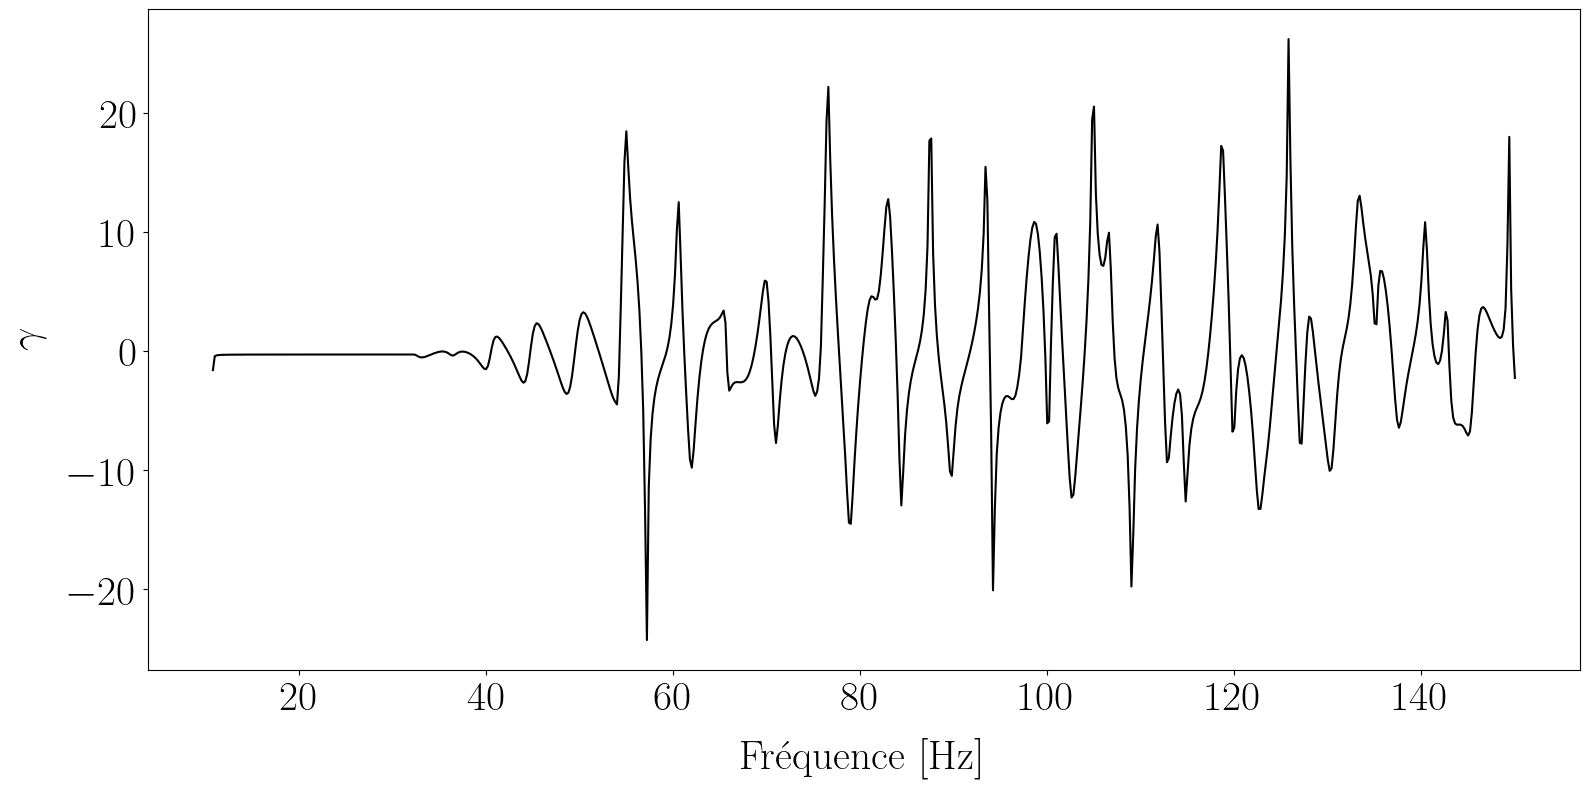

In [ ]:
# gamma = 20 * np.log10(np.abs(pi_21_r0))

# plt.figure(figsize=(16, 8))
# plt.plot(freq, gamma, color="k")
# plt.ylabel(r"$\gamma$")
# plt.xlabel("Fréquence [Hz]")

# # fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True)

# # # Amplitude
# # axs[0].plot(freq, np.abs(pi_21_r0), color="k", label="$\Pi(f)$")
# # axs[0].set_ylabel(r"$\lvert \Pi(f) \rvert$")

# # fig.supxlabel("Fréquence [Hz]")

In [63]:
gf1_r0.shape, freq.size

((751,), 751)

In [69]:
csdm = np.empty((freq.size, 4, 4),dtype=np.complex64)

for i_f, f in enumerate(freq):
    csdm_f = np.asarray(
        [
            [
                gf1_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf2_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf3_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf4_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
        ]
    )
    csdm[i_f, ...] = csdm_f

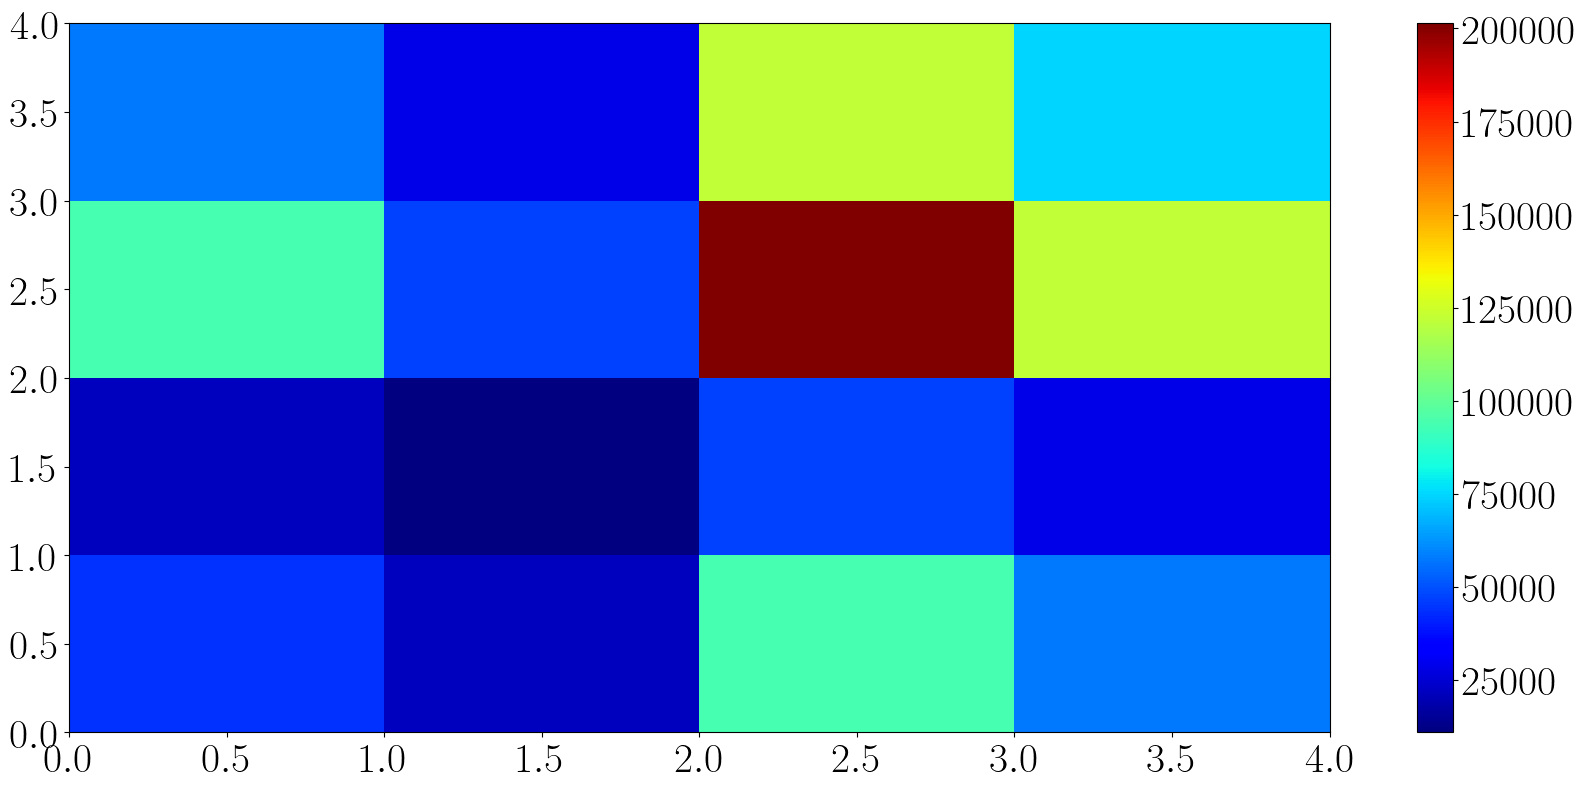

In [78]:
f0 = 100
idx_f0 = np.argmin(np.abs(f0 - freq))
csdm_f0 = csdm[idx_f0]


plt.figure()
im = plt.pcolormesh(
    # rcv_i,
    # rcv_i,
    np.abs(csdm_f0),
    cmap="jet",
    # vmin=0,
    # vmax=np.percentile(np.abs(csdm_f0), 30),
)
plt.colorbar(im)

In [79]:
from scipy.linalg import eigh

major_eigval, major_eigve = eigh(
    csdm_f0,
    check_finite=False,
)
major_eigve.shape, major_eigval

((4, 4),
 array([-6.2465779e-03,  2.1871574e-02,  6.2500000e-02,  3.3050022e+05],
       dtype=float32))

In [80]:
major_eigval = major_eigval[::-1]
major_eigve = major_eigve[:, -1]

Text(0, 0.5, 'Eigen value')

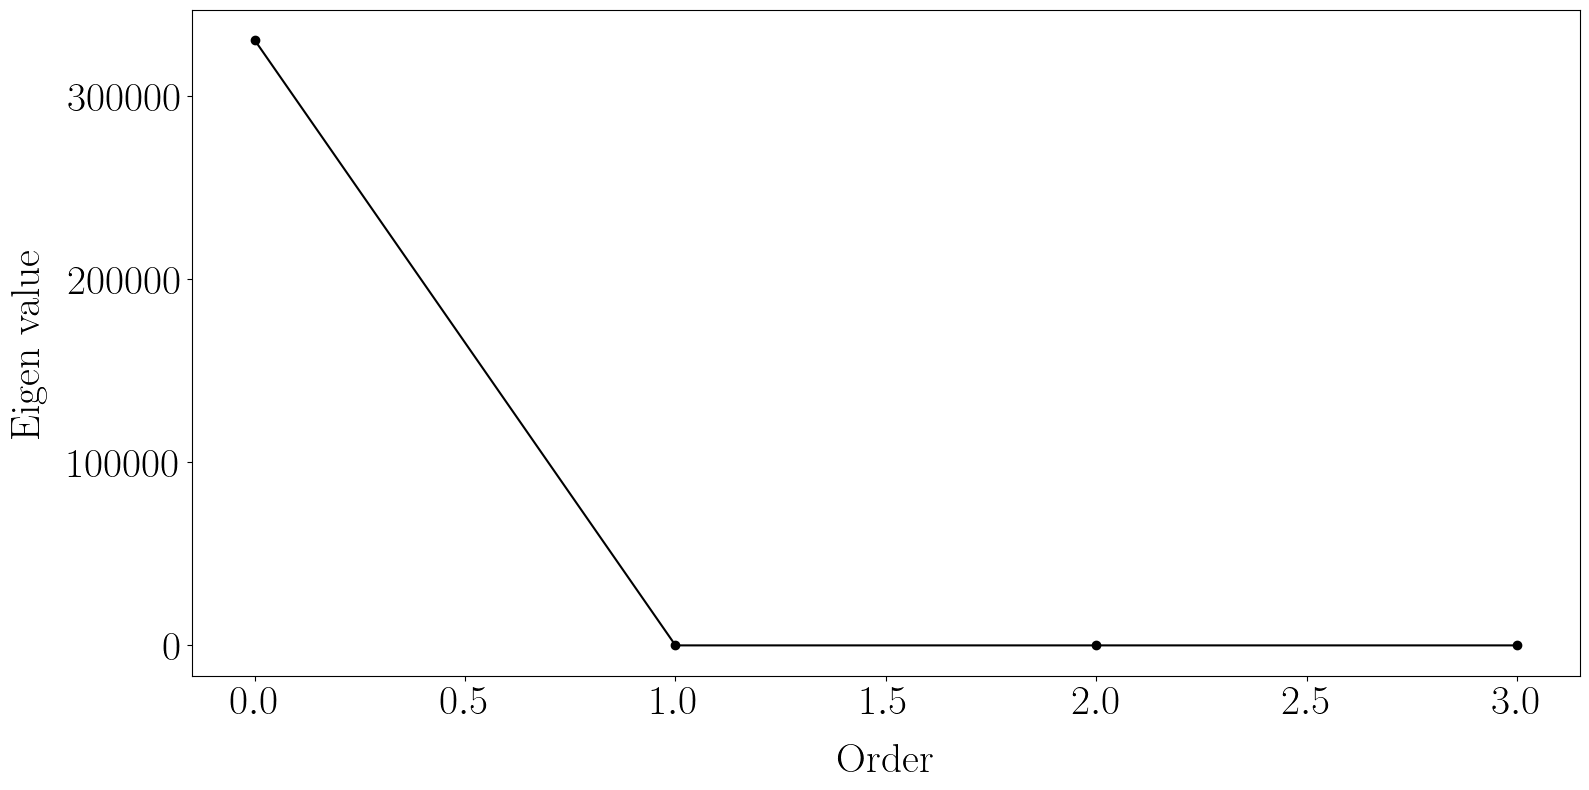

In [82]:
plt.figure()
plt.plot(major_eigval, "-o", color="k")
plt.xlabel("Order")
plt.ylabel("Eigen value")

Dans ce cas idéal (pas de bruit), la matrice de covariance est bien de rang 1 et possède donc une unique valeur propre non nulle.  

In [89]:
pi = major_eigve / major_eigve[0]
# pi
pi_th_f0 = np.asarray([1, pi_21_r0[idx_f0], pi_31_r0[idx_f0], pi_41_r0[idx_f0]])

Text(0, 0.5, 'Im')

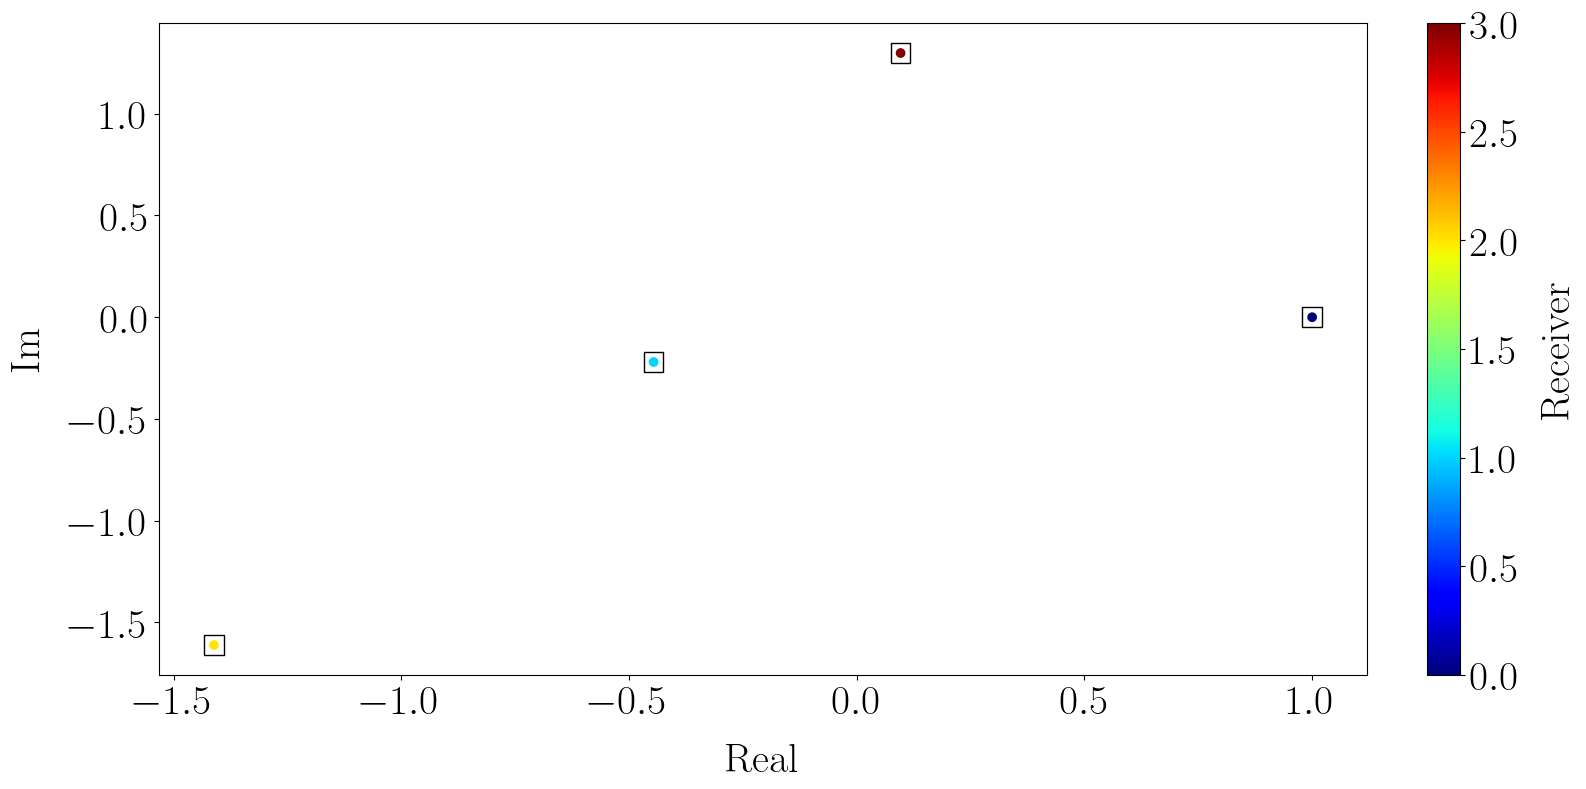

In [100]:
im = plt.scatter(np.real(pi), np.imag(pi), c=np.arange(pi.size), cmap="jet", label="CS-EVD")
plt.colorbar(im, label="Receiver")
im = plt.scatter(
    np.real(pi_th_f0),
    np.imag(pi_th_f0),
    marker="s",
    s=200,
    color="k",
    label="CS-EVD",
    facecolors='none'
)
# plt.legend()
plt.xlabel("Real")
plt.ylabel("Im")

On peut bien évidemment vérifier que les valeurs données par le vecteur propre principal de la CSDM et les valeurs théoriques de $\Pi$ coïncident. 

In [102]:
pi = np.empty((freq.size, 4), dtype=np.complex64)
pi_th = np.empty((freq.size, 4), dtype=np.complex64)

for i_f, f in enumerate(freq):

    csdm_fi = csdm[i_f]

    major_eigval, major_eigve = eigh(
        csdm_fi,
        check_finite=False,
    )
    major_eigve.shape, major_eigval

    major_eigval = major_eigval[::-1]
    major_eigve = major_eigve[:, -1]

    pi[i_f] = major_eigve / major_eigve[0]
    pi_th[i_f] = np.asarray([1, pi_21_r0[i_f], pi_31_r0[i_f], pi_41_r0[i_f]])

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\700839273.py:17: RuntimeWarning: divide by zero encountered in divide
  pi[i_f] = major_eigve / major_eigve[0]
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\700839273.py:17: RuntimeWarning: invalid value encountered in divide
  pi[i_f] = major_eigve / major_eigve[0]


On peut vérifier que cela coïncide également sur toute la plage de valeur. 

Text(0.5, 0.01, 'Fréquence [Hz]')

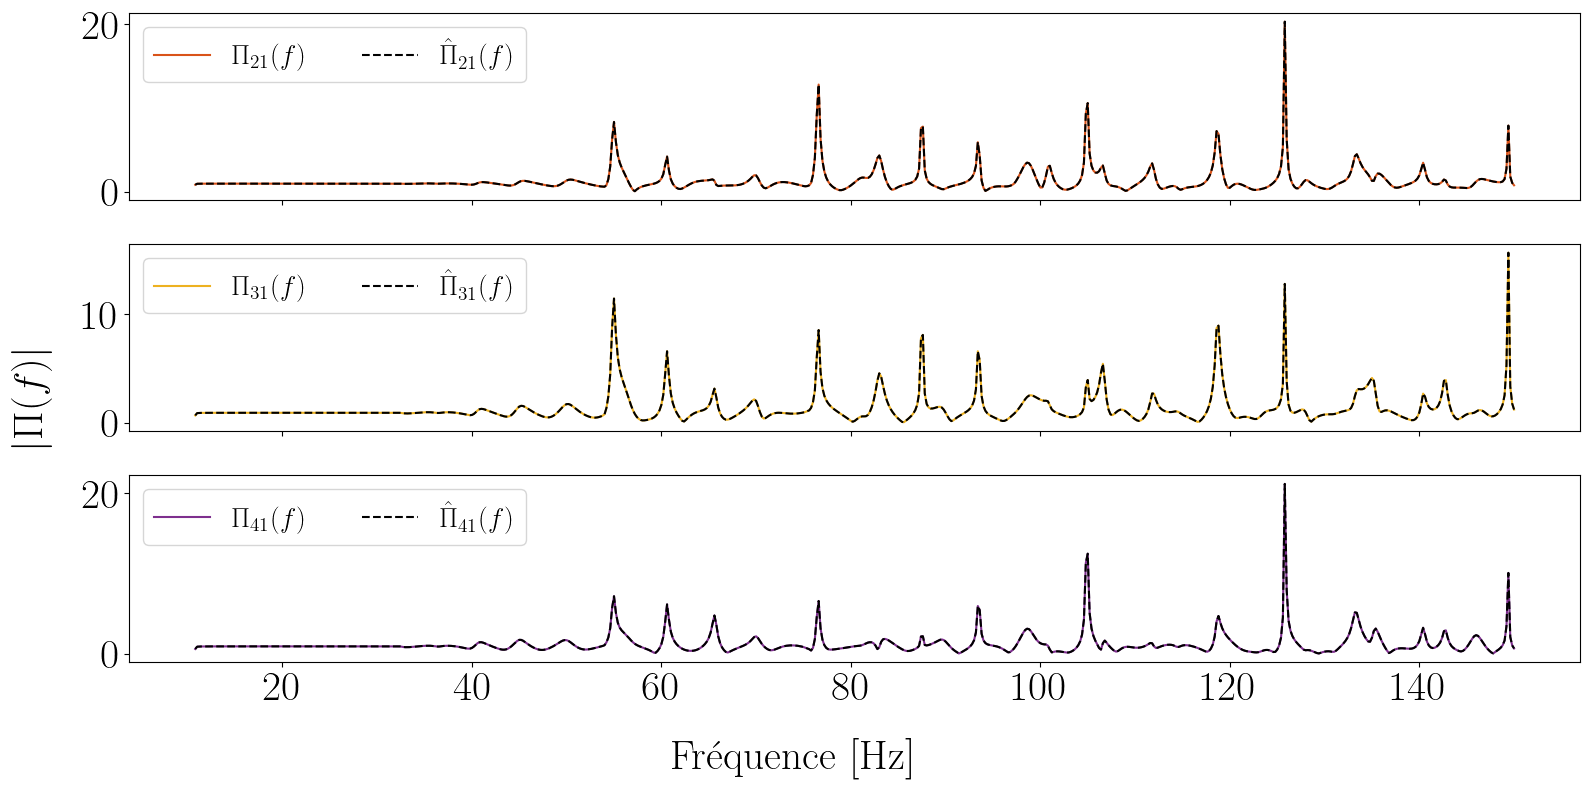

In [111]:
fig, axs = plt.subplots(3, 1, figsize=(16, 8), sharex=True)

# Amplitude
axs[0].plot(freq, np.abs(pi_th[:, 1]), color=color(1), label="$\Pi_{21}(f)$")
axs[0].plot(freq, np.abs(pi[:, 1]), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")
axs[0].legend(ncols=2, loc="upper left")

axs[1].plot(freq, np.abs(pi_th[:, 2]), color=color(2), label="$\Pi_{31}(f)$")
axs[1].plot(
    freq, np.abs(pi[:, 2]), color="k", label="$\hat{\Pi}_{31}(f)$", linestyle="--"
)
axs[1].legend(ncols=2, loc="upper left")


axs[2].plot(freq, np.abs(pi_th[:, 3]), color=color(3), label="$\Pi_{41}(f)$")
axs[2].plot(
    freq, np.abs(pi[:, 3]), color="k", label="$\hat{\Pi}_{41}(f)$", linestyle="--"
)
axs[2].legend(ncols=2, loc="upper left")

fig.supylabel(r"$\lvert \Pi(f) \rvert$")
fig.supxlabel("Fréquence [Hz]")

## Test avec une réponse à 0
A présent pour tester on peut mettre les données du capteur 2 à 0. 

In [250]:
csdm = np.empty((freq.size, 4, 4),dtype=np.complex64)

for i_f, f in enumerate(freq):
    csdm_f = np.asarray(
        [
            [
                gf1_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf1_r0[i_f] * 0,
                gf1_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                0 * np.conj(gf1_r0[i_f]),
                0 * np.conj(gf2_r0[i_f]),
                0 * np.conj(gf3_r0[i_f]),
                0 * np.conj(gf4_r0[i_f]),
            ],
            [
                gf3_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf3_r0[i_f] * 0,
                gf3_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf4_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf4_r0[i_f] * 0,
                gf4_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
        ]
    )
    csdm[i_f, ...] = csdm_f

[[ 43881.9       +0.j        0.        -0.j   -61930.27  +70716.3j
    4224.8423-56982.07j]
 [    -0.        +0.j        0.        -0.j        0.        -0.j
       0.        +0.j  ]
 [-61930.27  -70716.3j      -0.        +0.j   201362.14      +0.j
  -97789.91  +73610.08j]
 [  4224.8423+56982.07j      0.        +0.j   -97789.91  -73610.08j
   74399.83      +0.j  ]]


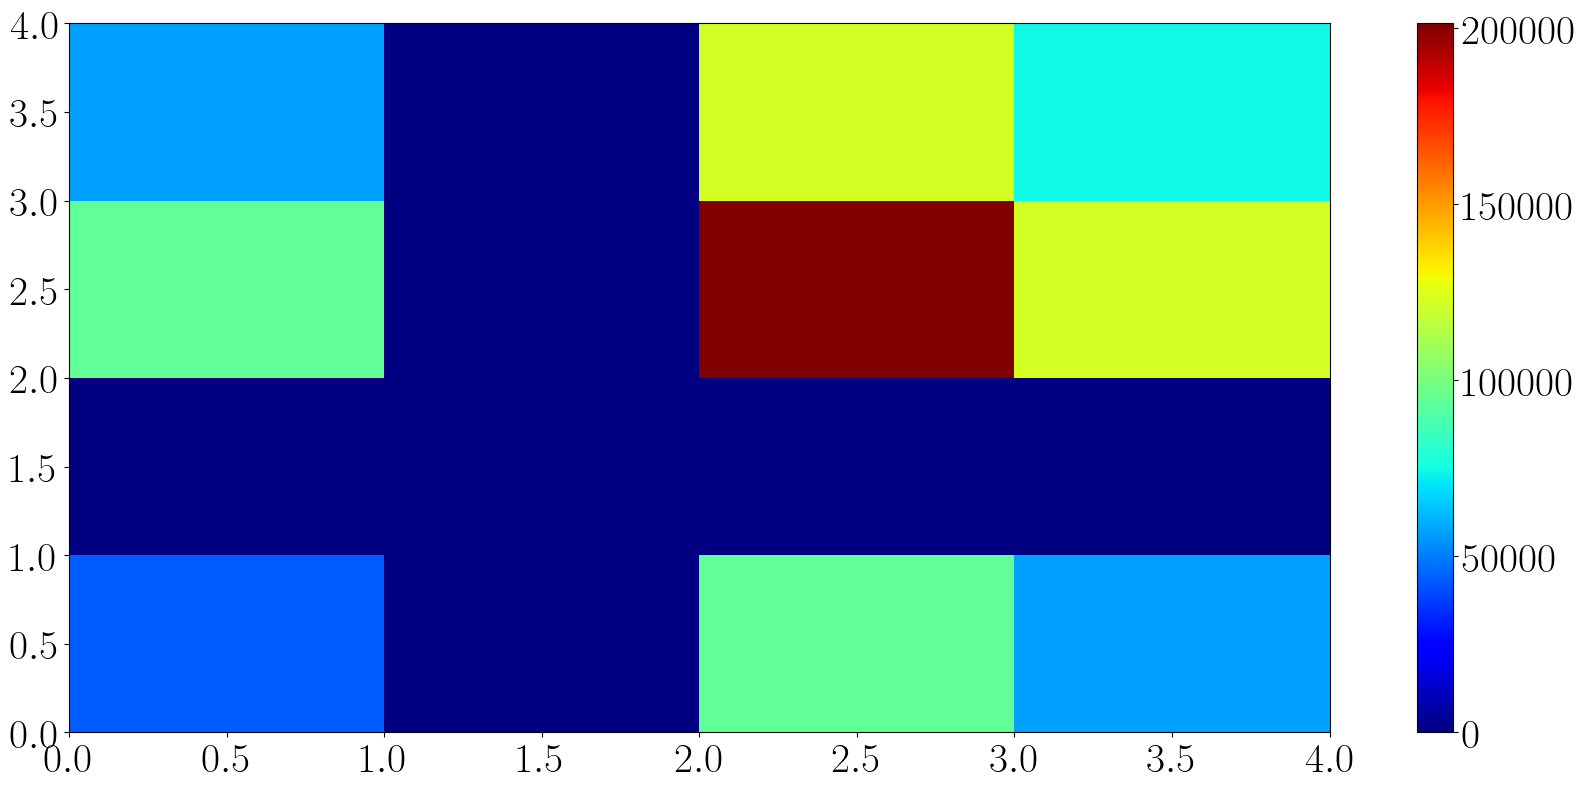

In [251]:
f0 = 100
idx_f0 = np.argmin(np.abs(f0 - freq))
csdm_f0 = csdm[idx_f0]

print(csdm_f0)
plt.figure()
im = plt.pcolormesh(
    # rcv_i,
    # rcv_i,
    np.abs(csdm_f0),
    cmap="jet",
    # vmin=0,
    # vmax=np.percentile(np.abs(csdm_f0), 30),
)
plt.colorbar(im)

[ 0.37051818-0.j          0.        +0.j         -0.5229101 -0.5970952j
  0.03567259+0.48112985j] [ 3.1964384e+05  6.2500000e-02  7.8989081e-03 -7.8989081e-03]


Text(0, 0.5, 'Eigen value')

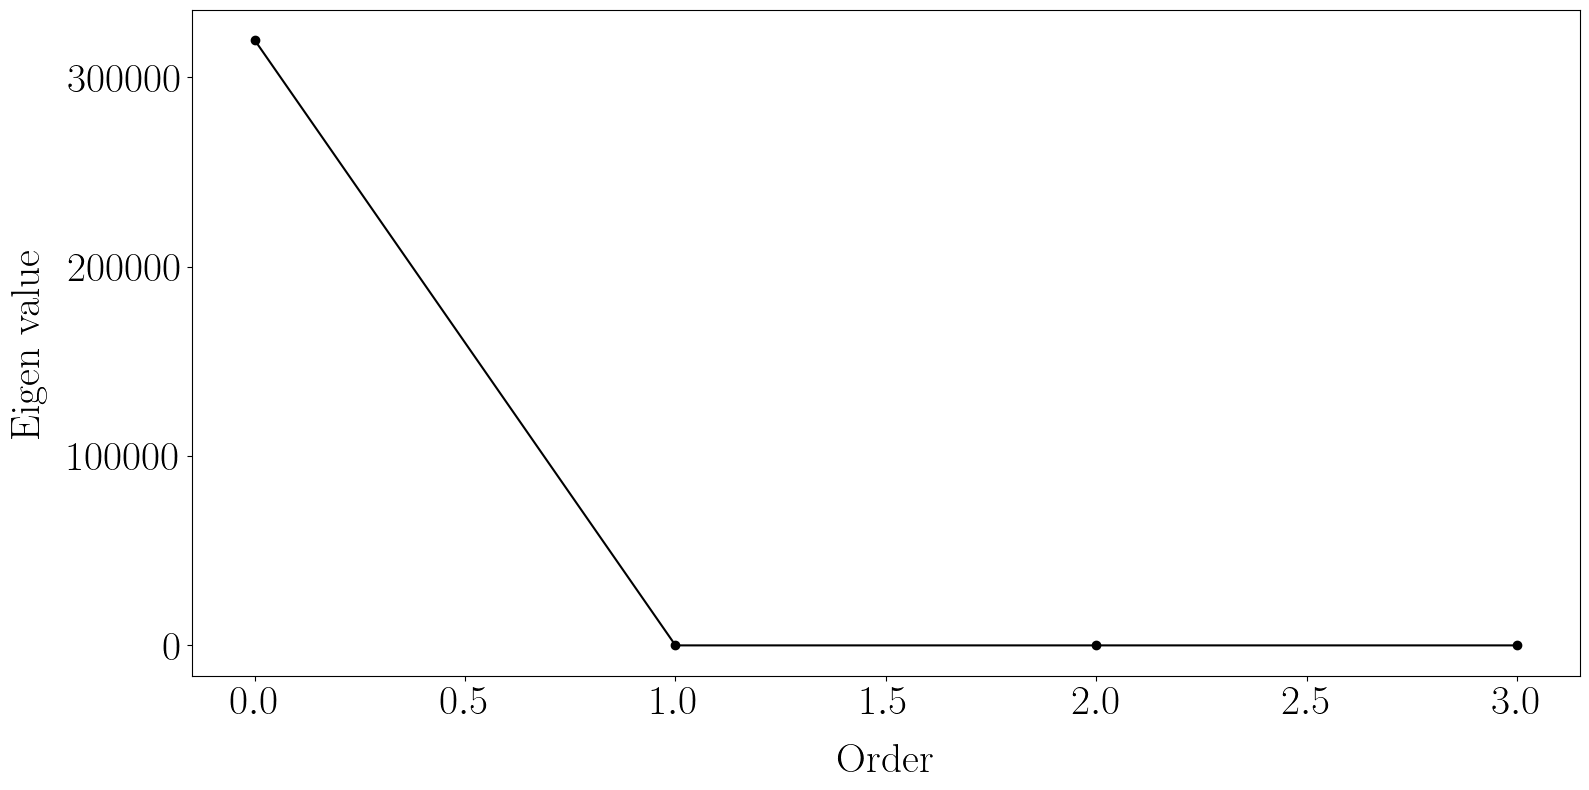

In [252]:
major_eigval, major_eigve = eigh(
    csdm_f0,
    check_finite=False,
)
major_eigve.shape, major_eigval

major_eigval = major_eigval[::-1]
major_eigve = major_eigve[:, -1]
print(major_eigve, major_eigval)

plt.figure()
plt.plot(major_eigval, "-o", color="k")
plt.xlabel("Order")
plt.ylabel("Eigen value")

In [253]:
pi = np.empty((freq.size, 4), dtype=np.complex64)
pi_th = np.empty((freq.size, 4), dtype=np.complex64)

for i_f, f in enumerate(freq):

    csdm_fi = csdm[i_f]

    major_eigval, major_eigve = eigh(
        csdm_fi,
        check_finite=False,
    )
    major_eigve.shape, major_eigval

    major_eigval = major_eigval[::-1]
    major_eigve = major_eigve[:, -1]

    pi[i_f] = major_eigve / major_eigve[0]
    pi_th[i_f] = np.asarray([1, pi_21_r0[i_f], pi_31_r0[i_f], pi_41_r0[i_f]])

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\700839273.py:17: RuntimeWarning: divide by zero encountered in divide
  pi[i_f] = major_eigve / major_eigve[0]
C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\700839273.py:17: RuntimeWarning: invalid value encountered in divide
  pi[i_f] = major_eigve / major_eigve[0]


Text(0.5, 0.01, 'Fréquence [Hz]')

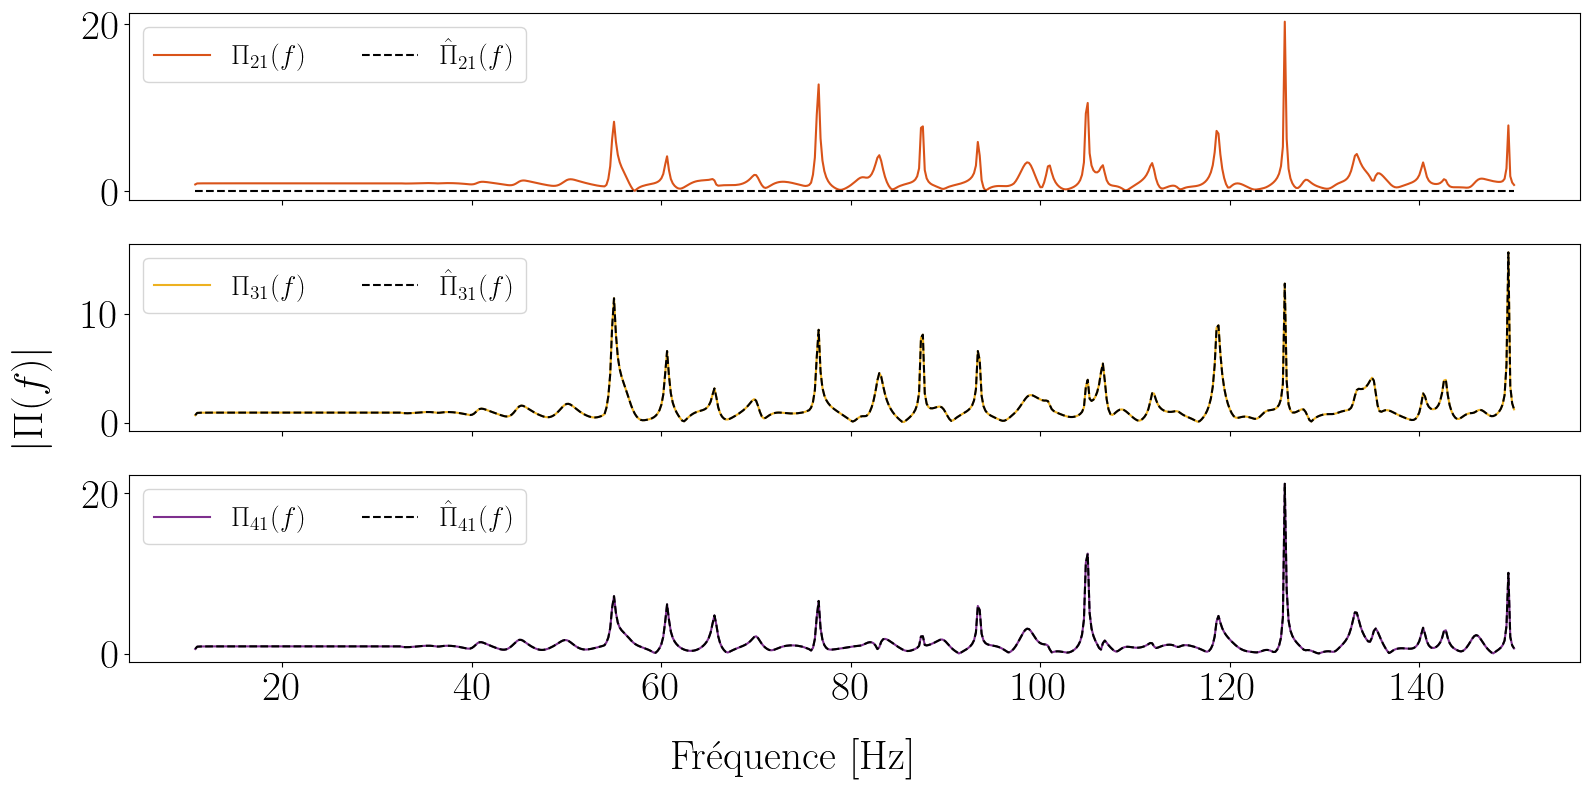

In [254]:
fig, axs = plt.subplots(3, 1, figsize=(16, 8), sharex=True)

# Amplitude
axs[0].plot(freq, np.abs(pi_th[:, 1]), color=color(1), label="$\Pi_{21}(f)$")
axs[0].plot(freq, np.abs(pi[:, 1]), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")
axs[0].legend(ncols=2, loc="upper left")

axs[1].plot(freq, np.abs(pi_th[:, 2]), color=color(2), label="$\Pi_{31}(f)$")
axs[1].plot(
    freq, np.abs(pi[:, 2]), color="k", label="$\hat{\Pi}_{31}(f)$", linestyle="--"
)
axs[1].legend(ncols=2, loc="upper left")


axs[2].plot(freq, np.abs(pi_th[:, 3]), color=color(3), label="$\Pi_{41}(f)$")
axs[2].plot(
    freq, np.abs(pi[:, 3]), color="k", label="$\hat{\Pi}_{41}(f)$", linestyle="--"
)
axs[2].legend(ncols=2, loc="upper left")

fig.supylabel(r"$\lvert \Pi(f) \rvert$")
fig.supxlabel("Fréquence [Hz]")

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\2129069207.py:5: RuntimeWarning: divide by zero encountered in log10
  axs[0].plot(freq, 20*np.log10(np.abs(pi[:, 1])), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")


Text(0.5, 0.01, 'Fréquence [Hz]')

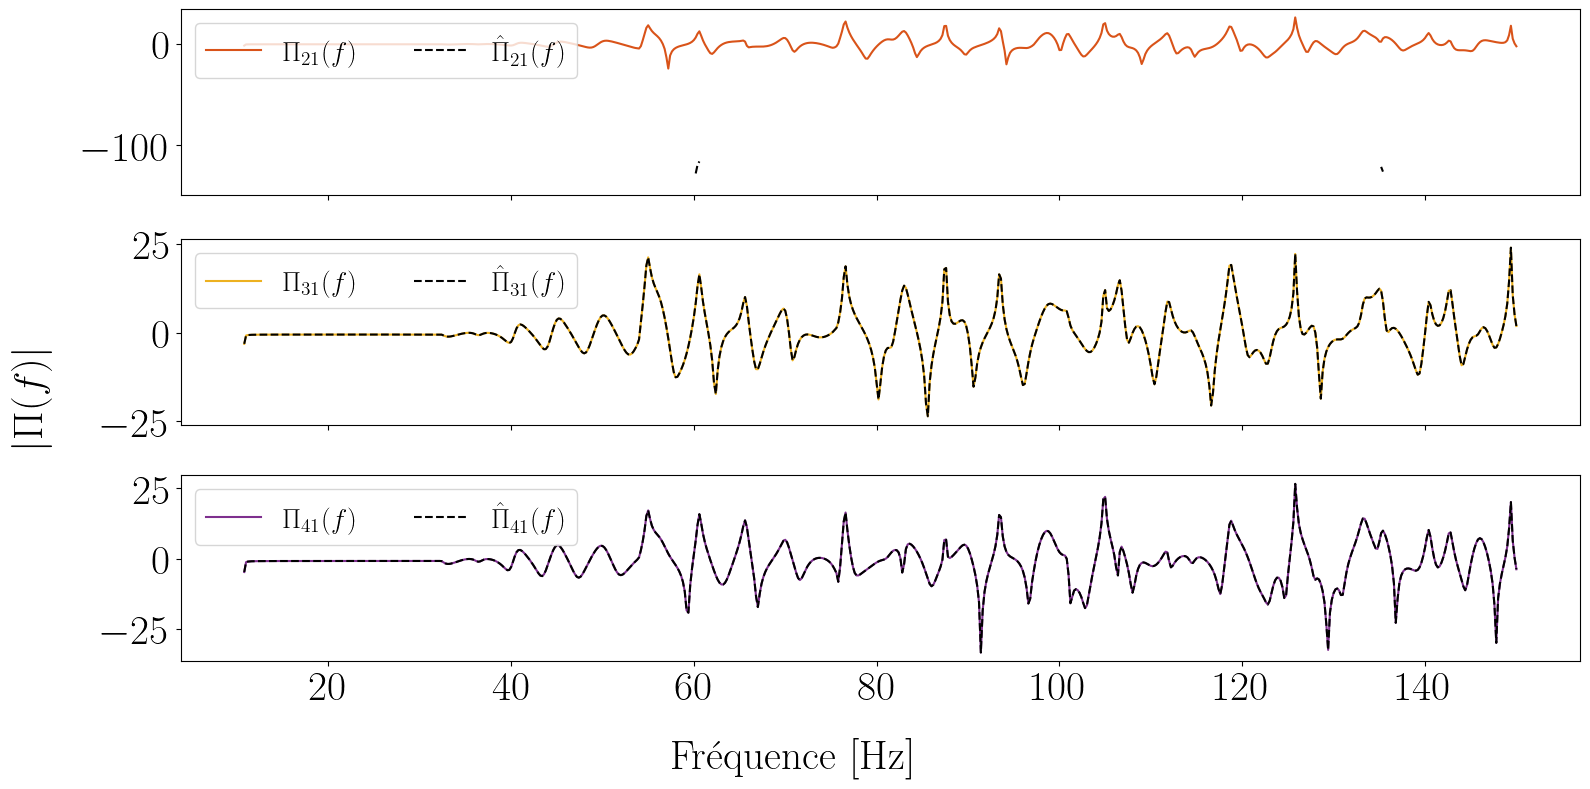

In [255]:
fig, axs = plt.subplots(3, 1, figsize=(16, 8), sharex=True)

# Amplitude
axs[0].plot(freq, 20*np.log10(np.abs(pi_th[:, 1])), color=color(1), label="$\Pi_{21}(f)$")
axs[0].plot(freq, 20*np.log10(np.abs(pi[:, 1])), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")
axs[0].legend(ncols=2, loc="upper left")

axs[1].plot(freq, 20*np.log10(np.abs(pi_th[:, 2])), color=color(2), label="$\Pi_{31}(f)$")
axs[1].plot(
    freq, 20*np.log10(np.abs(pi[:, 2])), color="k", label="$\hat{\Pi}_{31}(f)$", linestyle="--"
)
axs[1].legend(ncols=2, loc="upper left")


axs[2].plot(freq, 20*np.log10(np.abs(pi_th[:, 3])), color=color(3), label="$\Pi_{41}(f)$")
axs[2].plot(
    freq, 20*np.log10(np.abs(pi[:, 3])), color="k", label="$\hat{\Pi}_{41}(f)$", linestyle="--"
)
axs[2].legend(ncols=2, loc="upper left")

fig.supylabel(r"$\lvert \Pi(f) \rvert$")
fig.supxlabel("Fréquence [Hz]")

## Avec du bruit 

In [256]:
csdm = np.empty((freq.size, 4, 4), dtype=np.complex64)

for i_f, f in enumerate(freq):
    csdm_f = np.asarray(
        [
            [
                gf1_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf1_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf2_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf2_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf3_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf3_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
            [
                gf4_r0[i_f] * np.conj(gf1_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf2_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf3_r0[i_f]),
                gf4_r0[i_f] * np.conj(gf4_r0[i_f]),
            ],
        ]
    )
    csdm[i_f, ...] = csdm_f

alpha = 0.01
csdm_noise = np.random.normal(
    loc=0, scale=np.std(np.real(csdm)) * alpha, size=csdm.shape
) + 1j * np.random.normal(loc=0, scale=np.std(np.imag(csdm)) * alpha, size=csdm.shape)
csdm_noise, csdm
csdm = csdm + csdm_noise
csdm[:, 1, :] = 0 + 0 * 1j
csdm[:, :, 1] = 0 + 0 * 1j

[[ 43219.34273329-4.38860469e+01j      0.        +0.00000000e+00j
  -65508.92929485+7.21623537e+04j   4927.61983499-5.72125706e+04j]
 [     0.        +0.00000000e+00j      0.        +0.00000000e+00j
       0.        +0.00000000e+00j      0.        +0.00000000e+00j]
 [-61390.42996662-6.99591027e+04j      0.        +0.00000000e+00j
  202283.40224584+1.06711736e+03j -95688.95811555+7.42155184e+04j]
 [  3155.82123765+5.71706711e+04j      0.        +0.00000000e+00j
  -95923.53760375-7.33972348e+04j  71662.0284033 -8.00813803e+02j]]


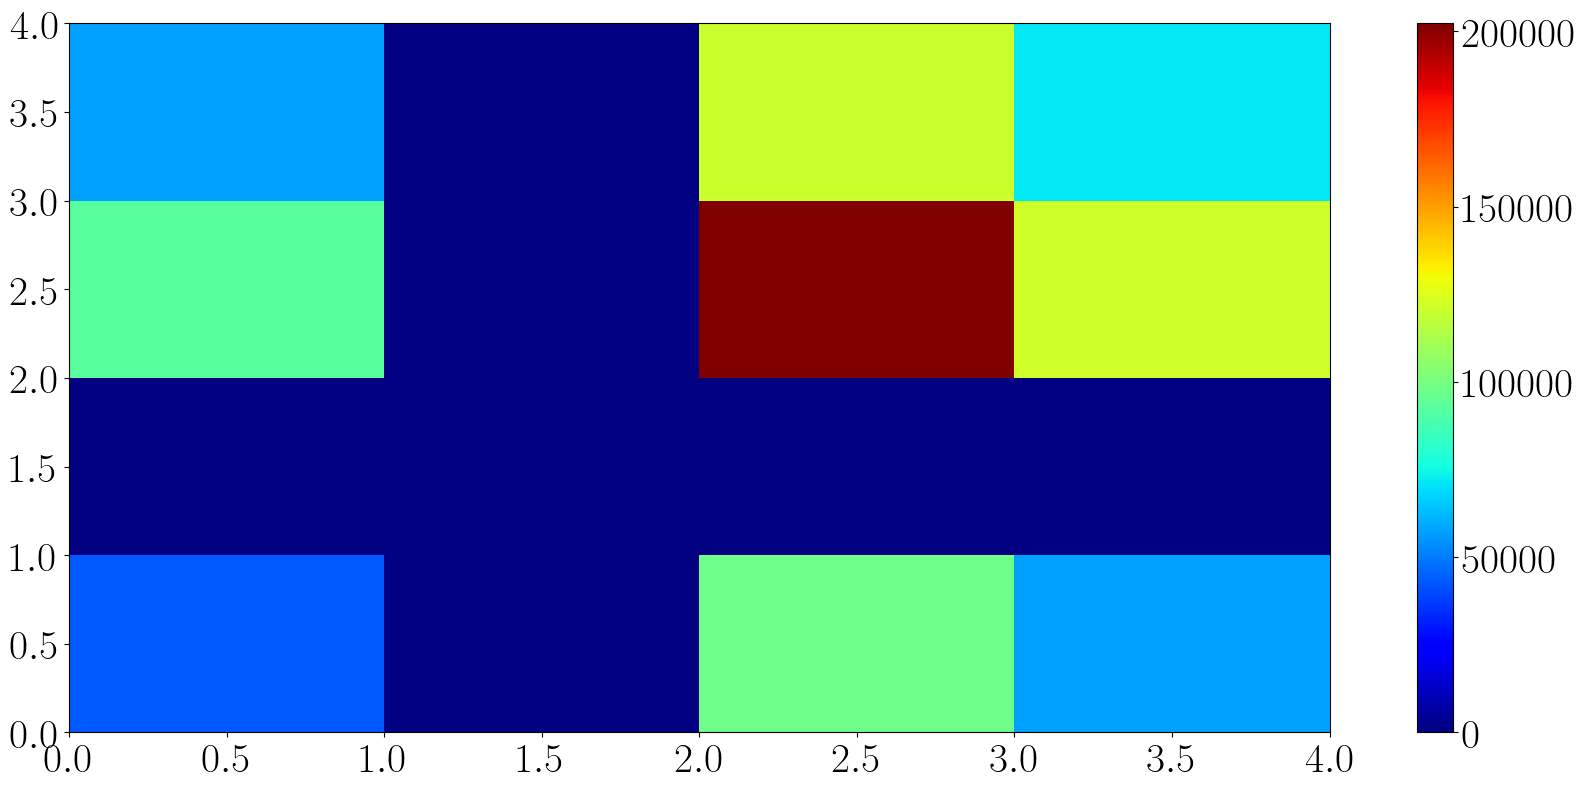

In [257]:
f0 = 100
idx_f0 = np.argmin(np.abs(f0 - freq))
csdm_f0 = csdm[idx_f0]

print(csdm_f0)
plt.figure()
im = plt.pcolormesh(
    # rcv_i,
    # rcv_i,
    np.abs(csdm_f0),
    cmap="jet",
    # vmin=0,
    # vmax=np.percentile(np.abs(csdm_f0), 30),
)
plt.colorbar(im)

[-3.69780511e-01-0.00000000e+00j  1.11022302e-16+6.80878964e-17j
  5.24130777e-01+6.00643523e-01j -2.98970255e-02-4.76322190e-01j] [ 3.17768978e+05  1.21389901e+03 -1.06865627e-11 -1.81810384e+03]


Text(0, 0.5, 'Eigen value')

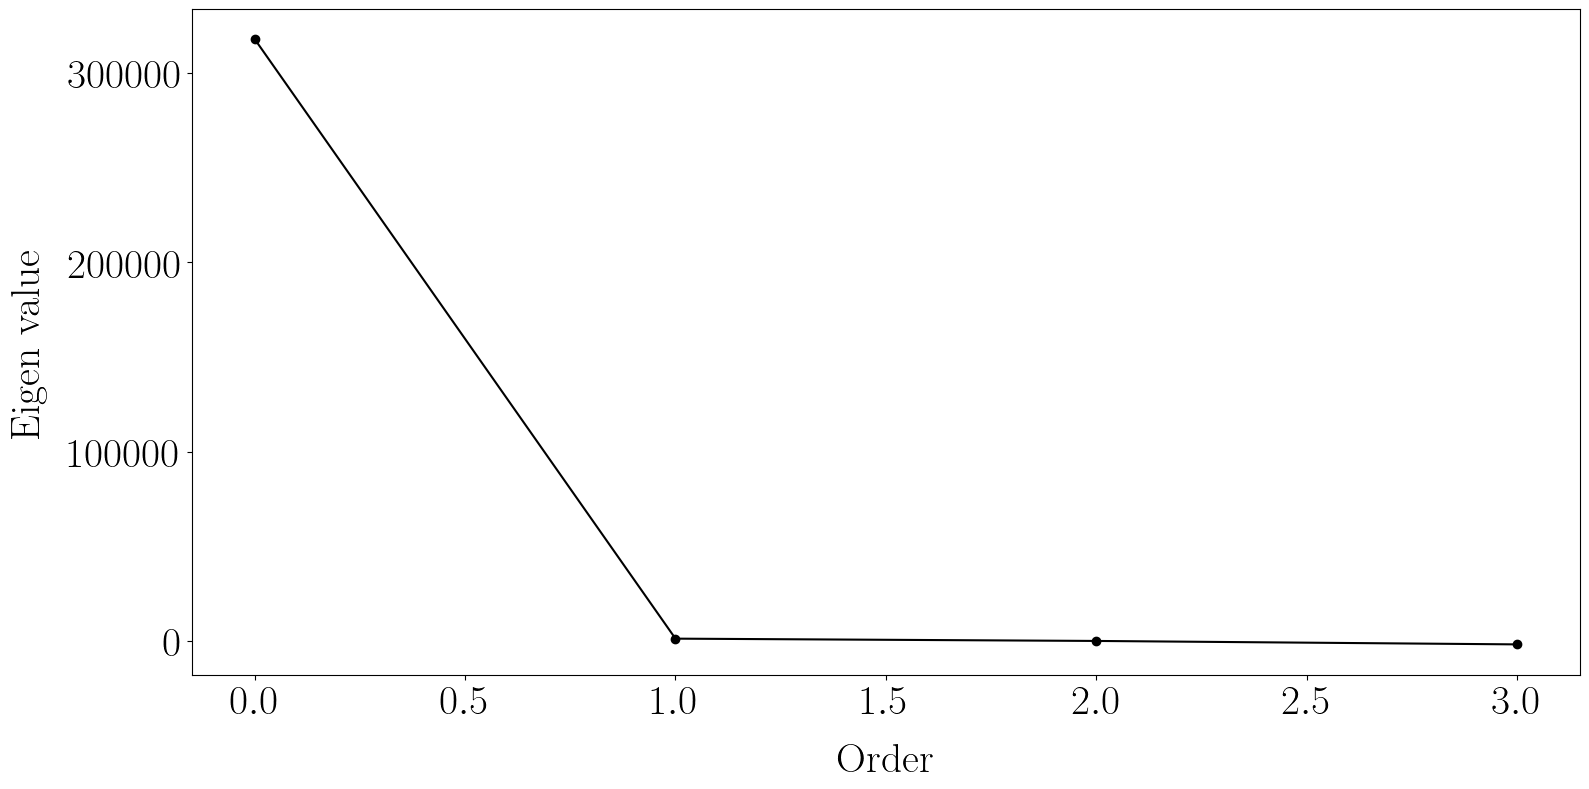

In [258]:
major_eigval, major_eigve = eigh(
    csdm_f0,
    check_finite=False,
)
major_eigve.shape, major_eigval

major_eigval = major_eigval[::-1]
major_eigve = major_eigve[:, -1]
print(major_eigve, major_eigval)

plt.figure()
plt.plot(major_eigval, "-o", color="k")
plt.xlabel("Order")
plt.ylabel("Eigen value")

In [259]:
pi = np.empty((freq.size, 4), dtype=np.complex64)
pi_th = np.empty((freq.size, 4), dtype=np.complex64)

for i_f, f in enumerate(freq):

    csdm_fi = csdm[i_f]

    major_eigval, major_eigve = eigh(
        csdm_fi,
        check_finite=False,
    )
    major_eigve.shape, major_eigval

    major_eigval = major_eigval[::-1]
    major_eigve = major_eigve[:, -1]

    pi[i_f] = major_eigve / major_eigve[0]
    pi_th[i_f] = np.asarray([1, pi_21_r0[i_f], pi_31_r0[i_f], pi_41_r0[i_f]])

In [260]:
np.abs(pi[:, 1])

array([2.15029743e-16, 8.65364487e-16, 5.78755180e-17, 5.28972969e-17,
       1.67561861e-17, 3.90195091e-17, 1.31243346e-17, 7.36292323e-17,
       1.62845724e-16, 1.44160058e-16, 2.05369855e-17, 1.05459655e-17,
       0.00000000e+00, 6.11413660e-17, 2.03053795e-16, 1.03522732e-16,
       3.17495576e-17, 4.59816236e-17, 2.61701099e-16, 1.25223300e-17,
       2.71514055e-16, 2.15641933e-17, 1.90329349e-16, 2.38089778e-17,
       1.19058236e-16, 1.35615186e-17, 1.68871013e-16, 5.28370153e-17,
       1.45948263e-16, 2.05727809e-17, 2.16546091e-16, 7.91047775e-16,
       0.00000000e+00, 7.53388657e-18, 1.90813379e-17, 6.67073254e-17,
       0.00000000e+00, 2.73882049e-17, 9.20058900e-17, 4.83478895e-17,
       3.09958525e-16, 4.63515752e-17, 1.15644604e-15, 2.89516391e-17,
       4.61496372e-16, 0.00000000e+00, 3.01506804e-16, 5.74042434e-17,
       2.22294877e-16, 2.66973244e-16, 1.63080147e-17, 1.49970823e-16,
       1.49543095e-15, 2.04335674e-16, 4.86169383e-16, 0.00000000e+00,
      

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\2129069207.py:5: RuntimeWarning: divide by zero encountered in log10
  axs[0].plot(freq, 20*np.log10(np.abs(pi[:, 1])), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")


Text(0.5, 0.01, 'Fréquence [Hz]')

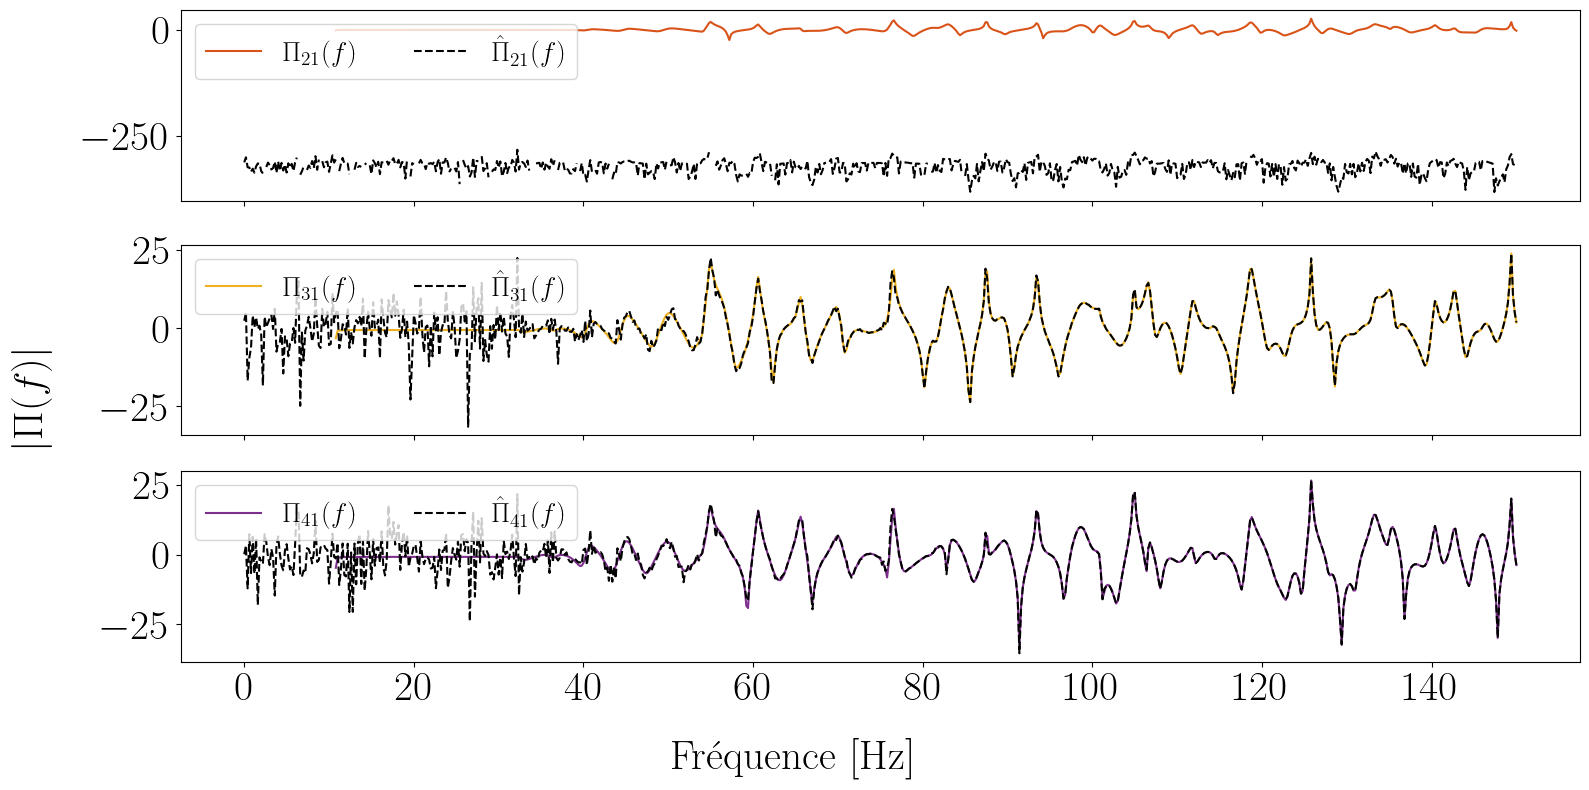

In [261]:
fig, axs = plt.subplots(3, 1, figsize=(16, 8), sharex=True)

# Amplitude
axs[0].plot(freq, 20*np.log10(np.abs(pi_th[:, 1])), color=color(1), label="$\Pi_{21}(f)$")
axs[0].plot(freq, 20*np.log10(np.abs(pi[:, 1])), color="k", label="$\hat{\Pi}_{21}(f)$", linestyle="--")
axs[0].legend(ncols=2, loc="upper left")

axs[1].plot(freq, 20*np.log10(np.abs(pi_th[:, 2])), color=color(2), label="$\Pi_{31}(f)$")
axs[1].plot(
    freq, 20*np.log10(np.abs(pi[:, 2])), color="k", label="$\hat{\Pi}_{31}(f)$", linestyle="--"
)
axs[1].legend(ncols=2, loc="upper left")


axs[2].plot(freq, 20*np.log10(np.abs(pi_th[:, 3])), color=color(3), label="$\Pi_{41}(f)$")
axs[2].plot(
    freq, 20*np.log10(np.abs(pi[:, 3])), color="k", label="$\hat{\Pi}_{41}(f)$", linestyle="--"
)
axs[2].legend(ncols=2, loc="upper left")

fig.supylabel(r"$\lvert \Pi(f) \rvert$")
fig.supxlabel("Fréquence [Hz]")

In [262]:
a = 20 * np.log10(np.abs(pi[:, 1]))
a[~np.isfinite(a)] = np.nan
mean = np.nanmean(a)

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\617808986.py:1: RuntimeWarning: divide by zero encountered in log10
  a = 20 * np.log10(np.abs(pi[:, 1]))


C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_28092\1676586772.py:7: RuntimeWarning: divide by zero encountered in log10
  20 * np.log10(np.abs(pi[:, 1])) - mean,


(60.0, 150.0)

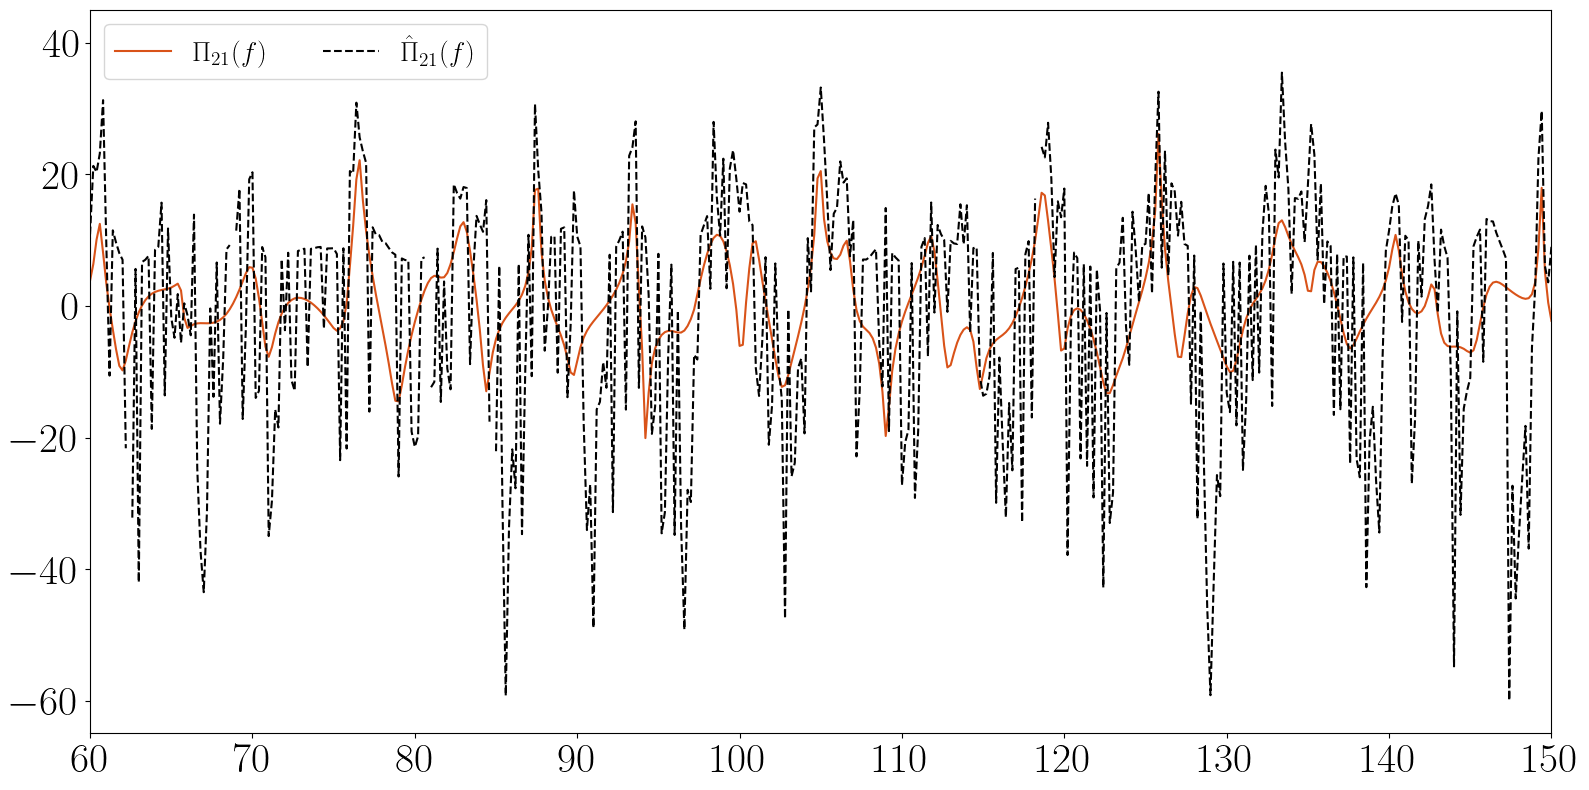

In [263]:
# Amplitude
plt.plot(
    freq, 20 * np.log10(np.abs(pi_th[:, 1])), color=color(1), label="$\Pi_{21}(f)$"
)
plt.plot(
    freq,
    20 * np.log10(np.abs(pi[:, 1])) - mean,
    color="k",
    label="$\hat{\Pi}_{21}(f)$",
    linestyle="--",
)
plt.legend(ncols=2, loc="upper left")
plt.xlim(60, 150)

Malgré la composante capteur 2 à 0, le vecteur estimer peut présenter des structures similaires au RTF théorique. Ces composantes communes sont elles les composantes du capteur 1 ? 